# Hand Sign Numbers: Train YOLO on Roboflow data and export TFLite
**Before running:** Runtime > Change runtime type > **T4 GPU**. Then run cells top to bottom.

In [1]:
!nvidia-smi
!pip install -q ultralytics roboflow
import ultralytics; ultralytics.checks()

Ultralytics 8.4.201 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 0.1/112.6 GB disk)


## 1. Settings (edit these)
Find them in Roboflow: open your project > Versions > Download Dataset > show download code.

In [2]:
from getpass import getpass
ROBOFLOW_API_KEY = getpass("Paste your Roboflow PRIVATE API key: ")  # hidden input

WORKSPACE = "kian-ambala"          # from your URL
PROJECT   = "handsign-numbers-7kisb"
VERSION   = 5                      # <-- your dataset version number

TASK      = "classify"             # your dataset is "folder" format = image classification
MODEL     = "yolo11s" if TASK == "detect" else "yolo11s-cls"   # s = good accuracy/speed balance. Use yolo11n for faster phones
IMGSZ     = 640 if TASK == "detect" else 224   # for realtime on phone you can use 320 (detect)
EPOCHS    = 100
BATCH     = 16

Paste your Roboflow PRIVATE API key: ··········


## 2. Download dataset

In [3]:
from roboflow import Roboflow
import os, shutil

rf = Roboflow(api_key=ROBOFLOW_API_KEY)
project = rf.workspace(WORKSPACE).project(PROJECT)
fmt = "yolov8" if TASK == "detect" else "folder"
dataset = project.version(VERSION).download(fmt)
print("Dataset at:", dataset.location)

if TASK == "detect":
    DATA = os.path.join(dataset.location, "data.yaml")
    # make paths absolute so Ultralytics never fails to find images
    import yaml
    with open(DATA) as f: cfg = yaml.safe_load(f)
    cfg["path"] = dataset.location
    cfg["train"] = "train/images"
    cfg["val"] = "valid/images" if os.path.exists(os.path.join(dataset.location,"valid")) else "val/images"
    if os.path.exists(os.path.join(dataset.location,"test/images")): cfg["test"] = "test/images"
    with open(DATA, "w") as f: yaml.safe_dump(cfg, f)
    print(open(DATA).read())
else:
    DATA = dataset.location
    v = os.path.join(DATA, "valid")
    if os.path.exists(v) and not os.path.exists(os.path.join(DATA, "val")):
        shutil.copytree(v, os.path.join(DATA, "val"))
    print(os.listdir(DATA))

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to HANDsign-NUMBERS-5 in folder:: 100%|██████████| 16402/16402 [00:08<00:00, 2002.16it/s]


Dataset at: /content/HANDsign-NUMBERS-5
['README.dataset.txt', 'README.roboflow.txt', 'valid', 'train', 'test', 'val']


## 3. Train

In [4]:
from ultralytics import YOLO

model = YOLO(f"{MODEL}.pt")
results = model.train(
    data=DATA,
    epochs=EPOCHS,
    imgsz=IMGSZ,
    batch=BATCH,
    patience=25,          # stop early if no improvement
    optimizer="auto",
    cos_lr=True,
    # augmentation for realtime camera robustness (lighting, angle, blur)
    hsv_h=0.015, hsv_s=0.7, hsv_v=0.4,
    degrees=10, translate=0.1, scale=0.5,
    fliplr=0.0,           # no mirroring: avoids confusing signs
    mosaic=1.0, close_mosaic=10,
    project="runs", name="handsign", exist_ok=True,
    workers=2, plots=True,
)

Ultralytics 8.4.201 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/content/HANDsign-NUMBERS-5, degrees=10, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=224, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11s-cls.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=handsign, nbs=64, nms=None, opset=None, optimize=False, opti

## 4. Check accuracy

Ultralytics 8.4.201 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11s-cls summary (fused): 47 layers, 5,446,938 parameters, 0 gradients, 12.1 GFLOPs
train: /content/HANDsign-NUMBERS-5/train... found 13050 images in 10 classes ✅ 
val: /content/HANDsign-NUMBERS-5/val... found 1650 images in 10 classes ✅ 
test: /content/HANDsign-NUMBERS-5/test... found 1700 images in 10 classes ✅ 
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 191.0±76.6 MB/s, size: 4.6 KB)
val: Scanning /content/HANDsign-NUMBERS-5/val... 1650 images, 0 corrupt: 100% ━━━━━━━━━━━━ 1650/1650 384.5Mit/s 0.0s
               classes   top1_acc   top5_acc: 100% ━━━━━━━━━━━━ 104/104 24.2it/s 4.3s
                   all          1          1
Speed: 0.1ms preprocess, 1.7ms inference, 0.0ms loss, 0.0ms postprocess per image
Results saved to /content/runs/classify/val
top1 accuracy: 1.000


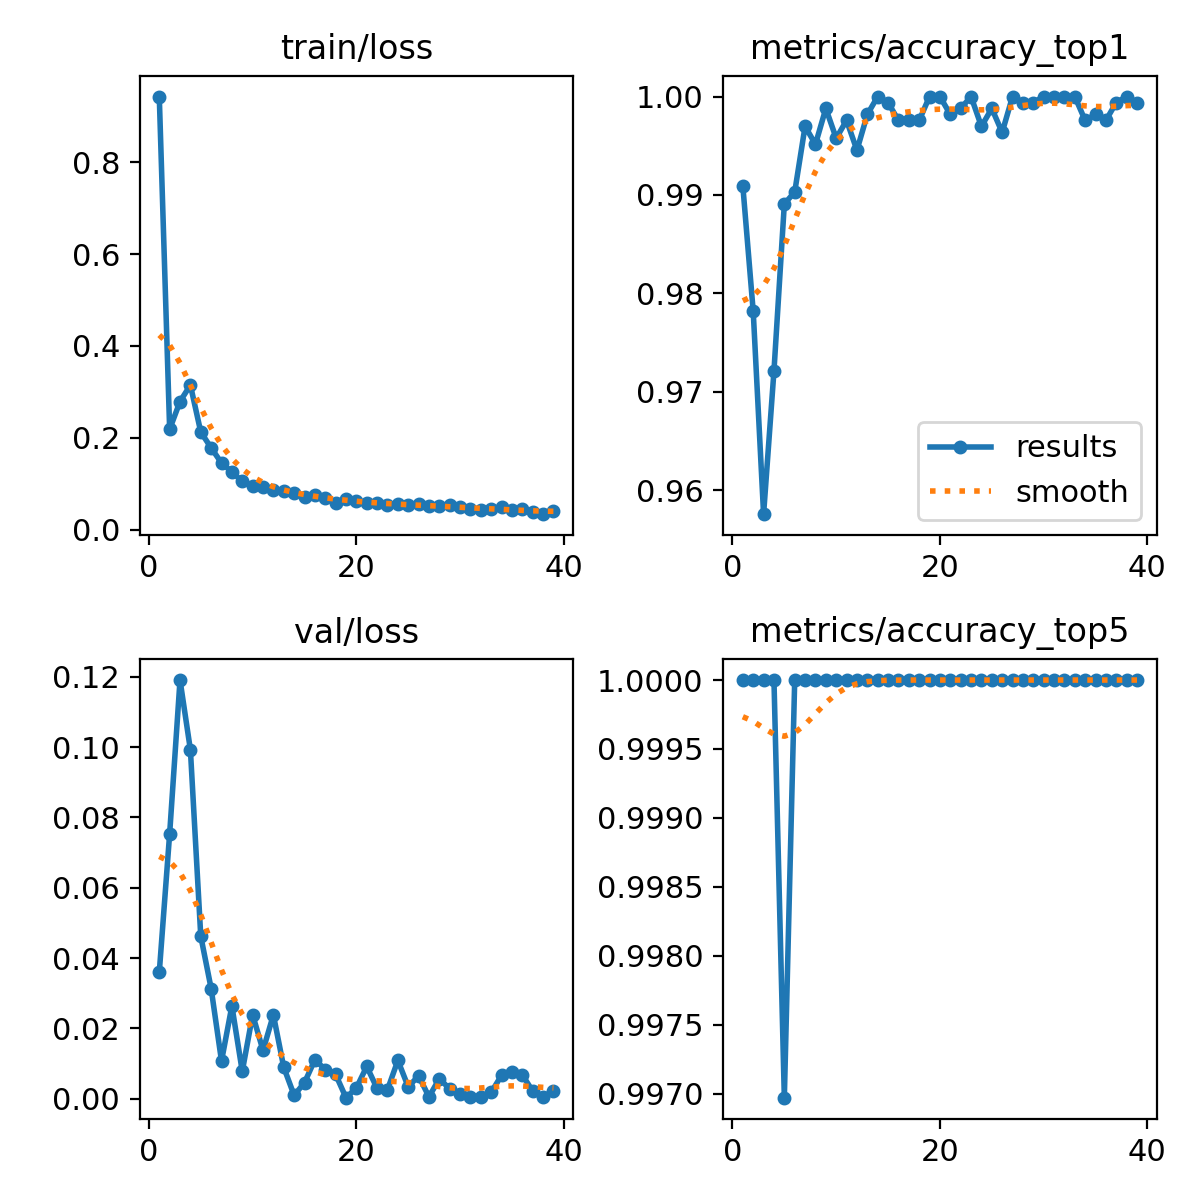

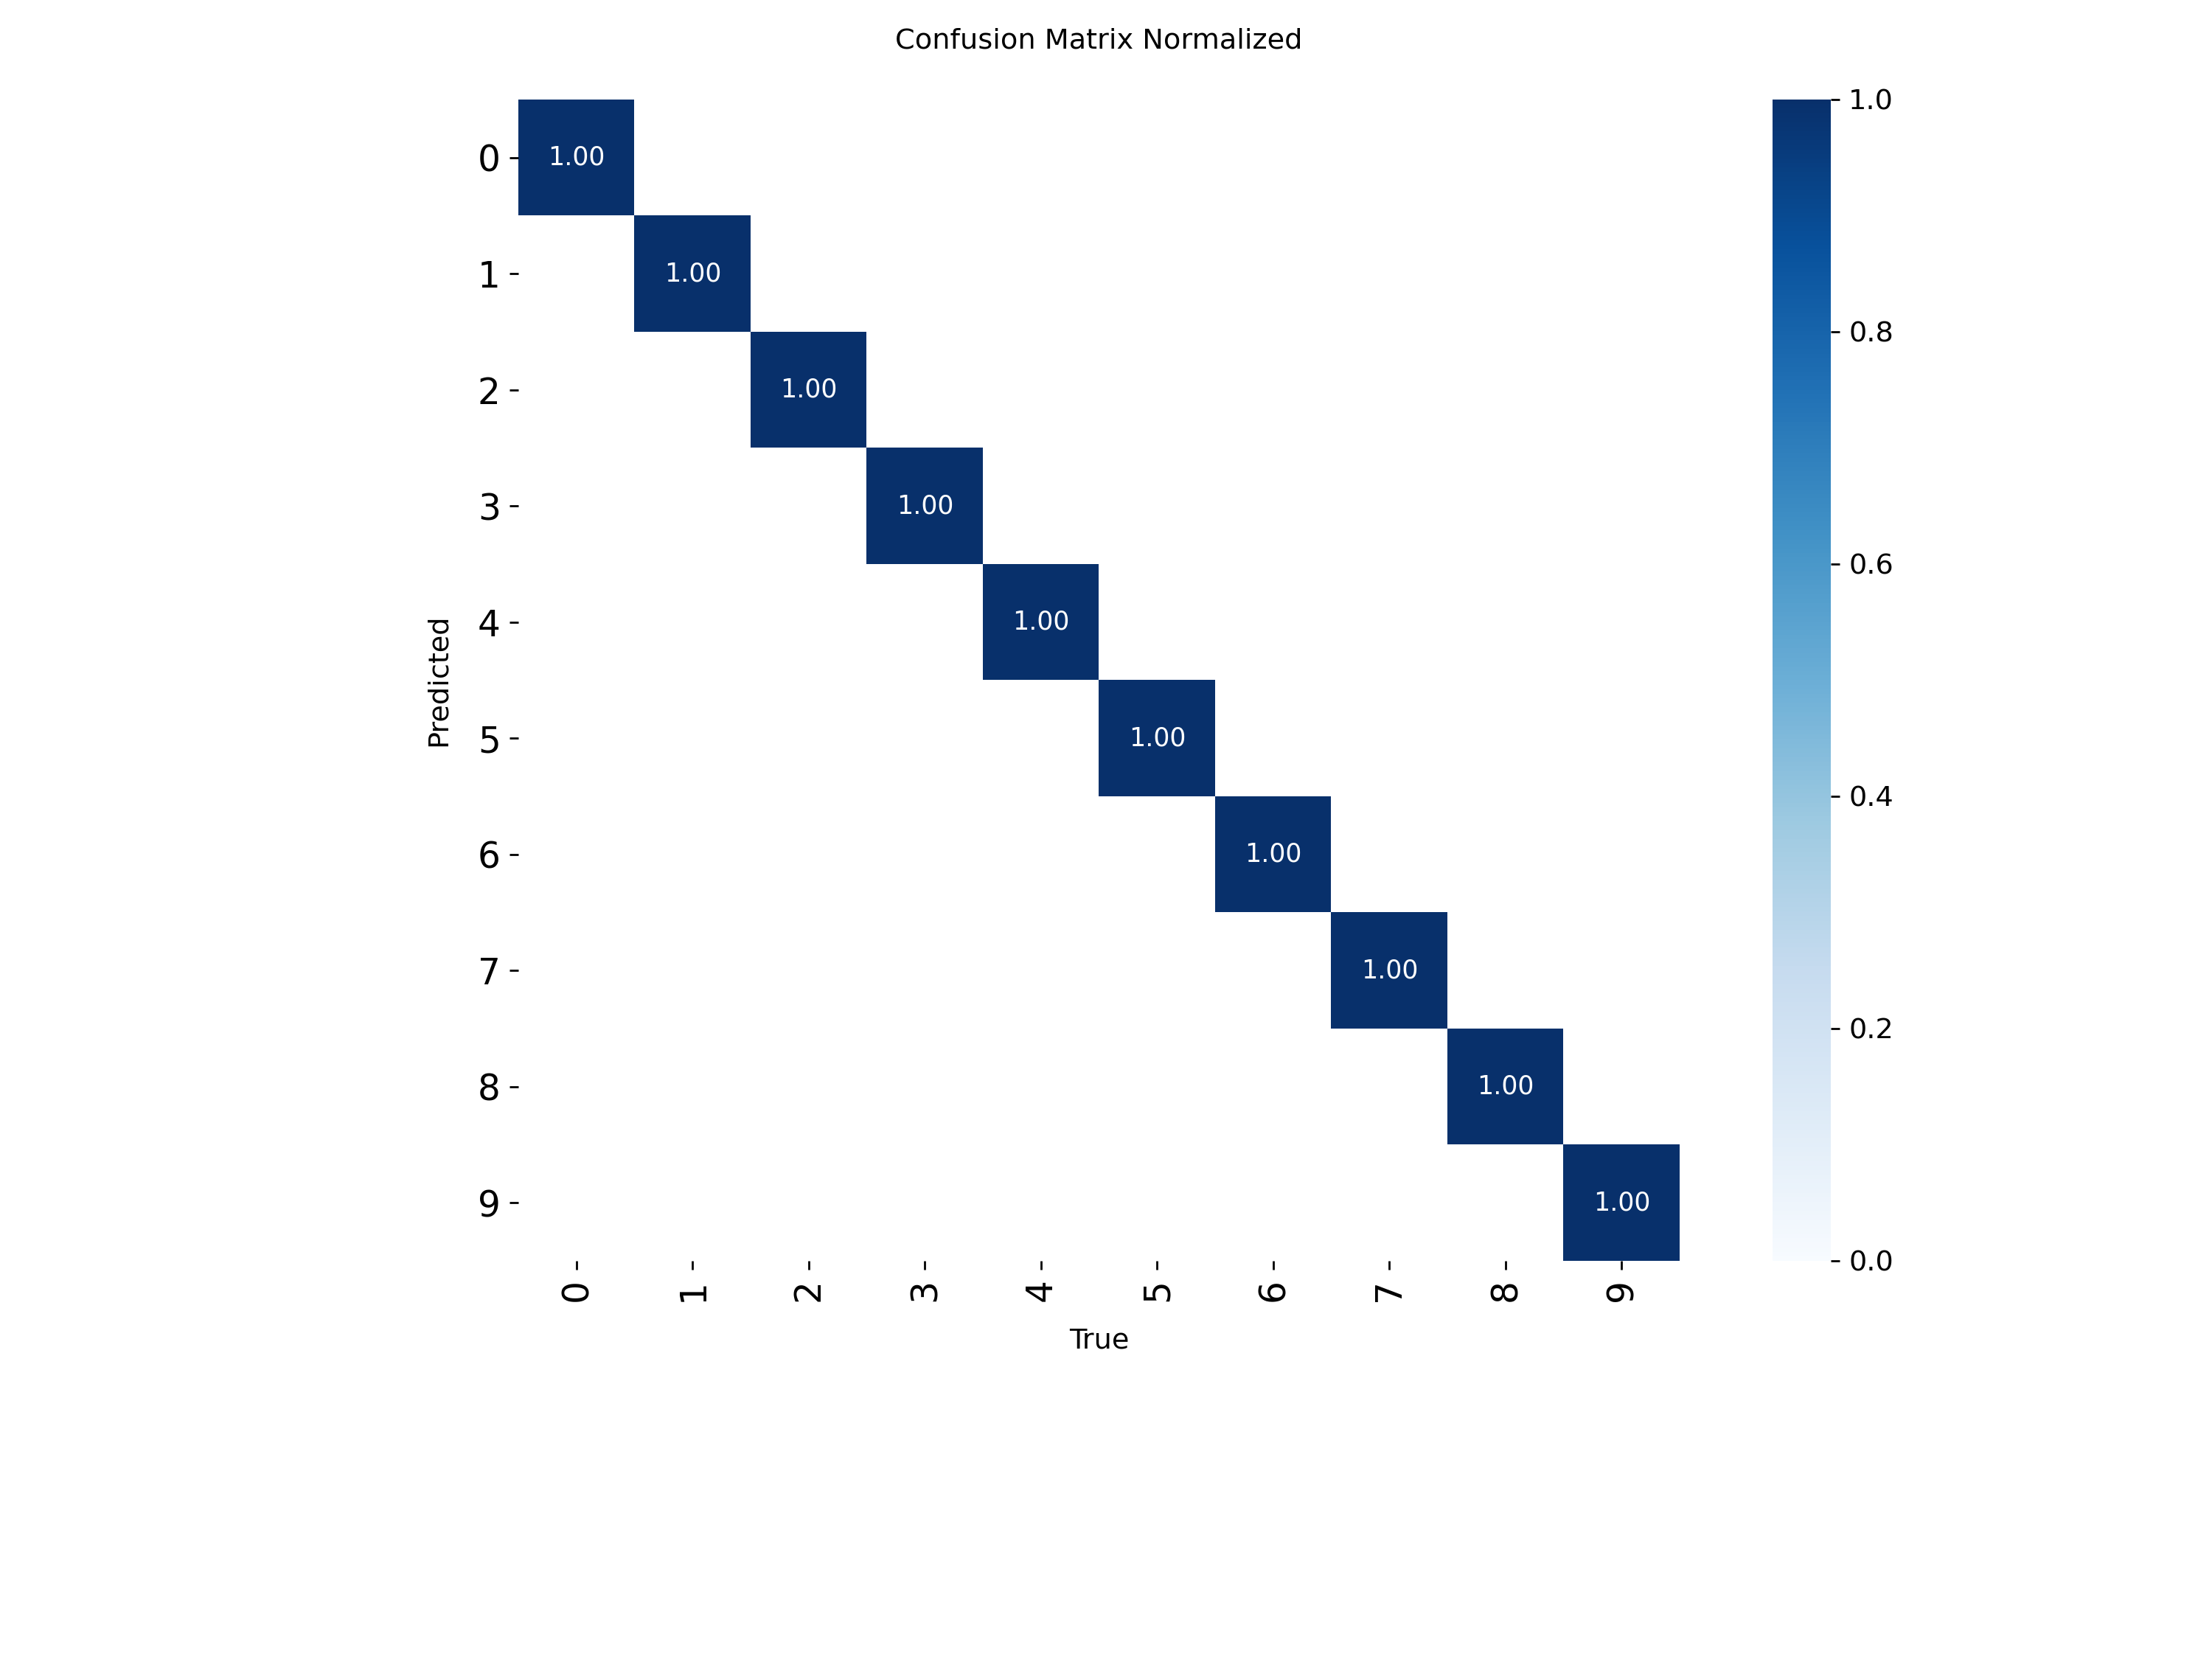

In [6]:
import os

# Adjust path based on whether it is a classification or detection task
if TASK == "classify":
    best_pt = "runs/classify/runs/handsign/weights/best.pt"
    results_dir = "runs/classify/runs/handsign"
else:
    best_pt = "runs/handsign/weights/best.pt"
    results_dir = "runs/handsign"

best = YOLO(best_pt)
metrics = best.val(data=DATA, imgsz=IMGSZ)
if TASK == "detect":
    print(f"mAP50: {metrics.box.map50:.3f}  mAP50-95: {metrics.box.map:.3f}")
else:
    print(f"top1 accuracy: {metrics.top1:.3f}")

from IPython.display import Image, display
for p in [f"{results_dir}/results.png", f"{results_dir}/confusion_matrix_normalized.png"]:
    if os.path.exists(p):
        display(Image(p))

## 5. Export to TFLite

In [8]:
import glob
exported = best.export(format="tflite", imgsz=IMGSZ, int8=False, half=False)
print("Export returned:", exported)

# Search for both .litert (LiteRT) and .tflite formats
tflites = glob.glob(f"{results_dir}/weights/**/*.tflite", recursive=True) + glob.glob(f"{results_dir}/weights/**/*.litert", recursive=True)
print(tflites)
assert tflites, "No model file (.tflite or .litert) produced, see log above"

TFLITE = next((t for t in tflites if "float32" in t), tflites[0])
print("Using:", TFLITE, round(os.path.getsize(TFLITE)/1e6,2), "MB")

WARNING ⚠️ 'int8' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ format='tflite' is deprecated as of 8.4.83 and has been replaced by the unified Google LiteRT format. Exporting format='litert' instead. See https://docs.ultralytics.com/integrations/litert
Ultralytics 8.4.201 🚀 Python-3.13.16 torch-2.11.0+cu130 CPU (Intel Xeon CPU @ 2.00GHz)
YOLO11s-cls summary (fused): 47 layers, 5,446,938 parameters, 0 gradients, 1.5 GFLOPs

PyTorch: starting from 'runs/classify/runs/handsign/weights/best.pt' with input shape (1, 3, 224, 224) BCHW and output shape(s) (1, 10) (10.5 MB)

LiteRT: starting export with litert_torch 0.10.0...


(00:00) [START] LiteRT-Torch Convert

(00:00) [START] LiteRT-Torch Convert > Torch Export: serving_default

(00:00) [START] LiteRT-Torch Convert > Torch Export: serving_default > ExportedProgram Run Decompositions

`isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


(00:01) [ DONE] LiteRT-Torch Convert > Torch Export: serving_default > ExportedProgram Run Decompositions (+00:01)

... (19 outputs left out)

(00:07) [ DONE] LiteRT-Torch Convert (+00:07)

(00:00) [START] Write Model to runs/classify/runs/handsign/weights/best.tflite

(00:00) [ DONE] Write Model to runs/classify/runs/handsign/weights/best.tflite (+00:00)

LiteRT: export success ✅ 7.6s, saved as 'runs/classify/runs/handsign/weights/best.tflite' (20.9 MB)

Export complete (7.9s)
Results saved to /content/runs/classify/runs/handsign/weights/best.tflite
Predict:         yolo predict task=classify model=runs/classify/runs/handsign/weights/best.tflite imgsz=224 
Validate:        yolo val task=classify model=runs/classify/runs/handsign/weights/best.tflite imgsz=224 data=/content/HANDsign-NUMBERS-5 
Visualize:       https://netron.app
Export returned: runs/classify/runs/handsign/weights/best.tflite
['runs/classify/runs/handsign/weights/best.tflite']
Using: runs/classify/runs/handsign/weights/best.tflite 21.87 MB


## 6. Test the TFLite model

Loading runs/classify/runs/handsign/weights/best.tflite for LiteRT inference...


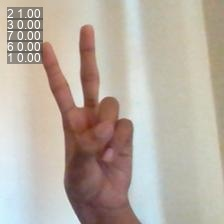

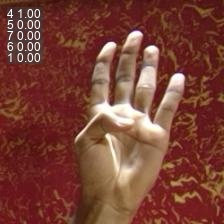

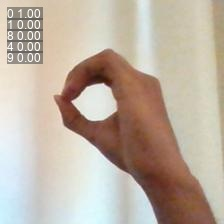

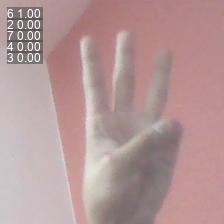

In [9]:
import random
if TASK == "detect":
    imgs = glob.glob(os.path.join(dataset.location, "valid/images/*")) or glob.glob(os.path.join(dataset.location, "val/images/*"))
else:
    imgs = glob.glob(os.path.join(DATA, "val/*/*"))
tfl = YOLO(TFLITE, task=TASK)
for p in random.sample(imgs, min(4, len(imgs))):
    r = tfl.predict(p, imgsz=IMGSZ, conf=0.4, verbose=False)[0]
    display(Image(r.save("pred.jpg")))

## 7. Download files

In [10]:
print(best.names)
with open("labels.txt","w") as f:
    for i in sorted(best.names): f.write(best.names[i]+"\n")

os.makedirs("final", exist_ok=True)
shutil.copy(TFLITE, "final/handsign.tflite")
shutil.copy("labels.txt", "final/labels.txt")
shutil.copy(best_pt, "final/best.pt")
!zip -r handsign_model.zip final
from google.colab import files
files.download("handsign_model.zip")

{0: '0', 1: '1', 2: '2', 3: '3', 4: '4', 5: '5', 6: '6', 7: '7', 8: '8', 9: '9'}
  adding: final/ (stored 0%)
  adding: final/best.pt (deflated 8%)
  adding: final/handsign.tflite (deflated 14%)
  adding: final/labels.txt (stored 0%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### 8. Test on a Custom Image
Upload any image to your Colab workspace directory (using the file explorer on the left) and run the cell below to test your LiteRT model.

Loading runs/classify/runs/handsign/weights/best.tflite for LiteRT inference...

image 1/1 /content/pred.jpg: 224x224 6 1.00, 2 0.00, 7 0.00, 4 0.00, 3 0.00, 34.1ms
Speed: 1.6ms preprocess, 34.1ms inference, 0.2ms postprocess per image at shape (1, 3, 224, 224)


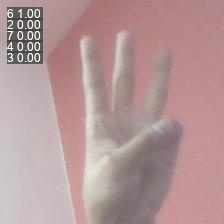

In [12]:
# Replace with the path to your uploaded image file
custom_image_path = "/content/pred.jpg"

import os
if os.path.exists(custom_image_path):
    # Load LiteRT model using YOLO API
    tfl_model = YOLO(TFLITE, task=TASK)

    # Run inference
    results = tfl_model.predict(custom_image_path, imgsz=IMGSZ, conf=0.25, verbose=True)[0]

    # Display the prediction
    display(Image(results.save("custom_pred.jpg")))
else:
    print(f"Please upload an image and update the custom_image_path. Currently '{custom_image_path}' does not exist.")

### 9. Interactive Image Upload and Test
Run the cell below to see an "Upload" button. Select an image from your computer to upload and test it with your trained model instantly!

Saving thumb (1).jpg to thumb (1) (1).jpg
User uploaded file "thumb (1) (1).jpg" with length 7043 bytes
Loading runs/classify/runs/handsign/weights/best.tflite for LiteRT inference...

🎯 RESULT: Predicted Hand Sign: 0 (100.00% Confidence)



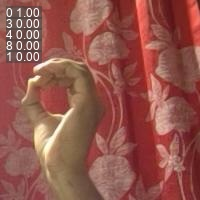

In [14]:
from google.colab import files
import os

uploaded = files.upload()

for fn in uploaded.keys():
    print(f'User uploaded file "{fn}" with length {len(uploaded[fn])} bytes')

    # Load LiteRT model using YOLO API
    tfl_model = YOLO(TFLITE, task=TASK)

    # Run inference
    results = tfl_model.predict(fn, imgsz=IMGSZ, conf=0.25, verbose=False)[0]

    # Get the top class and confidence score
    probs = results.probs
    top1_class_idx = probs.top1
    top1_class_name = results.names[top1_class_idx]
    top1_confidence = probs.top1conf.item() * 100

    print("\n" + "="*40)
    print(f"🎯 RESULT: Predicted Hand Sign: {top1_class_name} ({top1_confidence:.2f}% Confidence)")
    print("="*40 + "\n")

    # Display the prediction image
    display(Image(results.save("uploaded_pred.jpg")))